# 2. Entrenamiento LoRA: dos configuraciones que difieren en un solo factor

Base: `Qwen/Qwen2.5-Coder-1.5B-Instruct`, bf16, gradient checkpointing, 1 época, lr 2e-4 coseno, batch efectivo 16,
r = 16, α = 32, dropout 0.05. Pérdida solo sobre los tokens de la SQL (el prompt se enmascara).

**Factor que cambia: los módulos donde se inserta LoRA.**

| | Config A `lora_attn` | Config B `lora_all` |
|---|---|---|
| Módulos | `q,k,v,o` (atención) | `q,k,v,o,gate,up,down` (atención + MLP) |

**Hipótesis (escrita antes de entrenar).** B tendrá menor loss de validación y mayor EX que A. En un modelo de 1.5B,
las capas MLP concentran la mayor parte de los parámetros y son donde se almacena el "conocimiento" de patrones
(dialecto MySQL, uso de `COMMENT`, estructura de CTE y ventanas); adaptar solo la atención cambia sobre todo *a qué
columnas mira* el modelo, pero no tanto *qué escribe*. Esperamos que A mejore sobre el baseline (copiar nombres de
columnas del esquema en lugar de inventarlos) y que B mejore además en preguntas medias/difíciles. Costo esperado
de B: ~4× parámetros entrenables y algo más de tiempo por paso.

In [1]:
import json, os, sys
from pathlib import Path
import pandas as pd
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ); sys.path.insert(0, "scripts")
PASOS_PESADOS = False  # True para regenerar todo (requiere MySQL 8.4.10 en Docker y GPU)
pd.set_option("display.max_colwidth", 120)

In [2]:
if PASOS_PESADOS:
    !python scripts/entrenar.py --nombre lora_attn --modulos attn --batch 1 --acum 16 --max_spider 4000
    !python scripts/entrenar.py --nombre lora_all  --modulos all  --batch 1 --acum 16 --max_spider 4000
    # modelo final (entregado): config B + 6 esquemas propios más (datos v2) + 2 épocas
    !python scripts/entrenar.py --nombre lora_final --modulos all --batch 1 --acum 16 --max_spider 3000 --epocas 2
filas = []
for n in ["lora_attn", "lora_all", "lora_final"]:
    m = json.loads(Path(f"resultados/metricas_{n}.json").read_text(encoding="utf8"))
    ev = [x["eval_loss"] for x in m["historial"] if "eval_loss" in x]
    tr = [x["loss"] for x in m["historial"] if "loss" in x]
    filas.append({"config": n, "módulos": ",".join(m["modulos"]), "parámetros entrenables": f'{m["parametros_entrenables"]:,}',
                  "% del modelo": m["porcentaje_entrenable"], "ejemplos": m["ejemplos"], "minutos": m["minutos_entrenamiento"],
                  "VRAM máx (GB)": m["vram_max_gb"], "loss train final": round(tr[-1], 4), "loss dev final": round(ev[-1], 4)})
pd.DataFrame(filas)

,config,módulos,parámetros entrenables,% del modelo,ejemplos,minutos,VRAM máx (GB),loss train final,loss dev final
0,lora_attn,"q_proj,k_proj,v_proj,o_proj","4,358,144",0.2815,6532,77.7,3.76,0.1455,0.1436
1,lora_all,"q_proj,k_proj,v_proj,o_proj,gate_proj,up_proj,down_proj","18,464,768",1.1820,6532,92.7,4.11,0.1197,0.1298
2,lora_final,"q_proj,k_proj,v_proj,o_proj,gate_proj,up_proj,down_proj","18,464,768",1.1820,6795,141.2,4.11,0.0637,0.1474


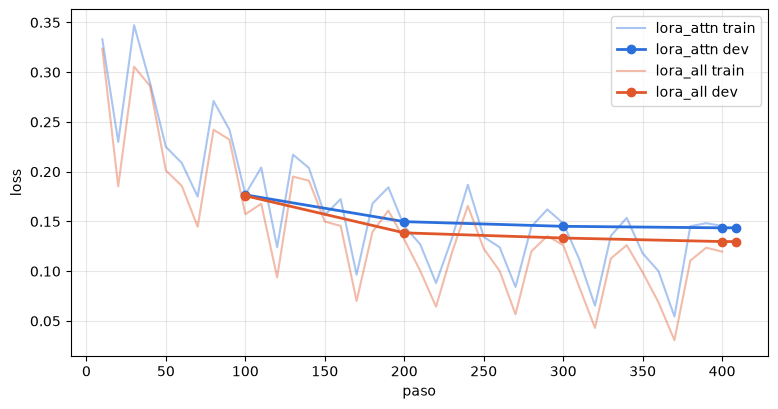

In [3]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 4.5))
for n, c in [("lora_attn", "#2a6fdb"), ("lora_all", "#e0572b")]:
    h = json.loads(Path(f"resultados/metricas_{n}.json").read_text(encoding="utf8"))["historial"]
    ax.plot([x["step"] for x in h if "loss" in x], [x["loss"] for x in h if "loss" in x], color=c, alpha=.4, label=f"{n} train")
    ax.plot([x["step"] for x in h if "eval_loss" in x], [x["eval_loss"] for x in h if "eval_loss" in x], color=c, lw=2, marker="o", label=f"{n} dev")
ax.set_xlabel("paso"); ax.set_ylabel("loss"); ax.grid(alpha=.3); ax.legend(); plt.show()

**Resultado:** se confirma la hipótesis. B baja más la loss de dev (0.130 frente a 0.144) y sube la EX de 0.388 a 0.450
(ver notebook 03), sobre todo en las preguntas medias. A arregla las fáciles y reduce las columnas inventadas, pero no
mejora las medias.

**Modelo final:** config B con 6 esquemas más (datos v2) y 2 épocas. Su dev incluye ejemplos de los esquemas nuevos, así
que no se compara directamente con A/B. Mínimo al final de la época 1 y leve subida en la 2; aun así la EX mejora.

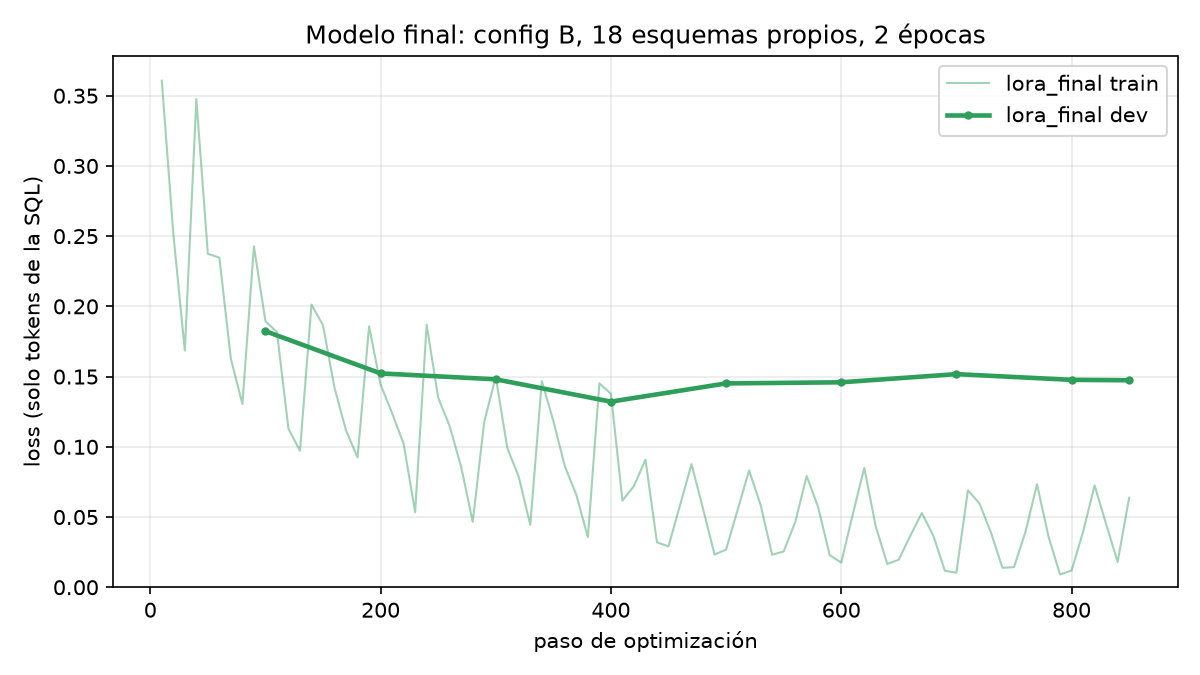

In [4]:
from IPython.display import Image
Image("resultados/curva_final.png")